### 01. Setup

In [1]:
import os
from pathlib import Path
import random
import time
import copy

from tqdm import tqdm
import numpy as np
import matplotlib.pyplot as plt

from IPython.display import display, clear_output

import torch
from torch import nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms
from torchinfo import summary

#### Reproducibility seeds

In [2]:
def set_seed(seed: int = 42) -> None:
    """Seed Python, NumPy, and PyTorch (CPU & all GPUs) and
    make cuDNN run in deterministic mode."""
    # ---- Python and NumPy -------------------------------------------
    random.seed(seed)
    np.random.seed(seed)

    # ---- PyTorch (CPU  &  GPU) --------------------------------------
    torch.manual_seed(seed)            
    torch.cuda.manual_seed_all(seed)   

    # ---- cuDNN: force repeatable convolutions -----------------------
    torch.backends.cudnn.deterministic = True 
    torch.backends.cudnn.benchmark     = False

In [3]:
set_seed(15)

PyTorch offsets each worker’s seed by default, injecting new randomness. For reproducible results, you want workers to start from **fixed** seeds so every data-augmentation decision (flip, crop, colour-jitter) is repeatable across runs. The `worker_init_fn` function re-seeds Python, NumPy, and PyTorch CPU random-number generators inside **each** worker using a simple deterministic formula (`SEED + worker_id`).  The result will be identical batches, identical gradients, and identical model checkpoints, run after run.

In [4]:
def worker_init_fn_(worker_id: int) -> None:
    """Re-seed each DataLoader worker so their RNGs don't collide."""
    worker_seed = 42 + worker_id
    np.random.seed(worker_seed) 
    random.seed(worker_seed)
    torch.manual_seed(worker_seed)

#### Data location

In [5]:
# make sure the data is downloaded,  extracted and split into train and test - if not please use the 01 notebook.
train_dir = Path("./data/train")
val_dir = Path("./data/test")

#### Hyperparameters and device

In [6]:
img_size = 64
batch_size = 32
lr = 0.001
epochs = 10 # set to low number for convenience. Change as needed.
model_name = "ai_capstone_pytorch_state_dict.pth"
num_classes = 2 # number of classes in the dataset

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device used is {device}")

Device used is cuda


### 01. Create the datasets

For datasets that follow a standard root/class_name/xxx.ext directory structure, PyTorch provides torchvision.datasets.ImageFolder. This is a specialized Dataset class that does all the work of finding image paths and inferring class labels for you. It's the most convenient way to load image datasets organized in folders, where each subfolder represents a different class. 

Custom transformations can be given as a parameter to the dataset creation to augment the collected data.


In cases when special treatment is needed one can create a custom dataset class inheriting from DataSet and customize the constructor, __getitem__ and __len__ methods: 

```python
class CustomBinaryClassDataset(Dataset):
    """A custom dataset for our agricultural land classification task."""

    def __init__(self, non_agri_dir, agri_dir, transform=None):
        """
        Args:
            non_agri_dir (Path): Directory with all the non-agricultural images.
            agri_dir (Path): Directory with all the agricultural images.
            transform (callable, optional): Optional transform to be applied on a sample.
        """
        self.transform = transform
        self.image_paths = []
        self.labels = []

        # Load non-agri paths and assign label 0
        for image_path in non_agri_dir.iterdir():
            self.image_paths.append(image_path)
            self.labels.append(0)

        # Load agri paths and assign label 1
        for image_path in agri_dir.iterdir():
            self.image_paths.append(image_path)
            self.labels.append(1)

        temp = list(zip(self.image_paths, self.labels))
        np.random.shuffle(temp)
        self.image_paths, self.labels = zip(*temp)

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image_path = self.image_paths[idx]
        image = Image.open(image_path).convert("RGB")

        label = self.labels[idx]

        # Apply transformations if they exist
        if self.transform:
            image = self.transform(image)

        return image, label
```


In [7]:
train_transform = transforms.Compose([ #transforms.Resize((64, 64)), # not really needed here as pictures are already 64x64, but potentially useful syntax
                                     transforms.RandomHorizontalFlip(p=0.5), # probability 0.5
                                     transforms.RandomVerticalFlip(p=0.5),   # probability 0.5
                                     transforms.RandomRotation(45),
                                     transforms.RandomAffine(0, shear=0.2),
                                     transforms.ToTensor(), # Converts PIL Image to a tensor, reorders to (channels, height, width) and scales values to [0, 1]
                                     transforms.Normalize(mean = [0.5, 0.5, 0.5], std = [0.5, 0.5, 0.5]) # Normalize from [0, 1] to [-1, 1]
])

val_transform = transforms.Compose([ #transforms.Resize((64, 64)), # not really needed here as pictures are already 64x64, but potentially useful syntax
                                     transforms.ToTensor(), # Converts PIL Image to a tensor, reorders to (channels, height, width) and scales values to [0, 1]
                                     transforms.Normalize(mean = [0.5, 0.5, 0.5], std = [0.5, 0.5, 0.5]) # Normalize from [0, 1] to [-1, 1]
])

In [8]:
train_dataset = datasets.ImageFolder(root=train_dir, transform=train_transform)
val_dataset = datasets.ImageFolder(root=val_dir, transform=val_transform)

In [9]:
print(f"Classes found by ImageFolder: {train_dataset.classes}")
print(f"Class to index mapping: {train_dataset.class_to_idx}")

Classes found by ImageFolder: ['class_0_non_agri', 'class_1_agri']
Class to index mapping: {'class_0_non_agri': 0, 'class_1_agri': 1}


### 02. Setting up the train and test data loaders

The dataloader can specify things like batch size and wether or not to shuffle (True during training, False during validation).

In [10]:
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=4, worker_init_fn=worker_init_fn_)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=4, worker_init_fn=worker_init_fn_)

In [11]:
images, labels = next(iter(train_loader))

print(f"Images batch shape: {images.shape}") 
print(f"Labels batch shape: {labels.shape}")


Images batch shape: torch.Size([32, 3, 64, 64])
Labels batch shape: torch.Size([32])


### 03. Making the model

In [12]:
my_model = nn.Sequential(
    # Conv Block 1: 64x64 -> 32x32
    nn.Conv2d(3, 32, kernel_size=3, padding=1),
    nn.BatchNorm2d(32),
    nn.ReLU(),
    nn.MaxPool2d(2),

    # Conv Block 2: 32x32 -> 16x16
    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.BatchNorm2d(64),
    nn.ReLU(),
    nn.MaxPool2d(2),

    # Conv Block 3: 16x16 -> 8x8
    nn.Conv2d(64, 128, kernel_size=3, padding=1),
    nn.BatchNorm2d(128),
    nn.ReLU(),
    nn.MaxPool2d(2),

    # Conv Block 4: 8x8 -> 4x4
    nn.Conv2d(128, 256, kernel_size=3, padding=1),
    nn.BatchNorm2d(256),
    nn.ReLU(),
    nn.MaxPool2d(2),

    # Classifier
    nn.AdaptiveAvgPool2d(1),
    nn.Flatten(),
    nn.Linear(256, 128),
    nn.ReLU(),
    nn.Dropout(0.4),
    nn.Linear(128, num_classes)
).to(device)

In [13]:
# Show model paramenters with torchinfo's summary

summary(my_model, input_size=(8, 3, 64, 64))

Layer (type:depth-idx)                   Output Shape              Param #
Sequential                               [8, 2]                    --
├─Conv2d: 1-1                            [8, 32, 64, 64]           896
├─BatchNorm2d: 1-2                       [8, 32, 64, 64]           64
├─ReLU: 1-3                              [8, 32, 64, 64]           --
├─MaxPool2d: 1-4                         [8, 32, 32, 32]           --
├─Conv2d: 1-5                            [8, 64, 32, 32]           18,496
├─BatchNorm2d: 1-6                       [8, 64, 32, 32]           128
├─ReLU: 1-7                              [8, 64, 32, 32]           --
├─MaxPool2d: 1-8                         [8, 64, 16, 16]           --
├─Conv2d: 1-9                            [8, 128, 16, 16]          73,856
├─BatchNorm2d: 1-10                      [8, 128, 16, 16]          256
├─ReLU: 1-11                             [8, 128, 16, 16]          --
├─MaxPool2d: 1-12                        [8, 128, 8, 8]            --
├─Co

In [14]:
ibm_model = nn.Sequential(
                        # Conv Block 1
                        nn.Conv2d(3, 32, 5, padding=2), nn.ReLU(),
                        nn.MaxPool2d(2), nn.BatchNorm2d(32),
                        
                        # Conv Block 2-6
                        nn.Conv2d(32, 64, 5, padding=2), nn.ReLU(), nn.MaxPool2d(2), nn.BatchNorm2d(64),
                        nn.Conv2d(64, 128, 5, padding=2), nn.ReLU(), nn.MaxPool2d(2), nn.BatchNorm2d(128),
                        nn.Conv2d(128, 256, 5, padding=2), nn.ReLU(), nn.MaxPool2d(2), nn.BatchNorm2d(256),
                        nn.Conv2d(256, 512, 5, padding=2), nn.ReLU(), nn.MaxPool2d(2), nn.BatchNorm2d(512),
                        nn.Conv2d(512, 1024, 5, padding=2), nn.ReLU(), nn.MaxPool2d(2), nn.BatchNorm2d(1024),
                        
                        # Classifier
                        nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                        nn.Linear(1024, 2048), nn.ReLU(), nn.BatchNorm1d(2048), nn.Dropout(0.4),
                        nn.Linear(2048, num_classes)
                    ).to(device)

In [15]:
# Show model paramenters with torchinfo's summary

summary(ibm_model, input_size=(8, 3, 64, 64))

Layer (type:depth-idx)                   Output Shape              Param #
Sequential                               [8, 2]                    --
├─Conv2d: 1-1                            [8, 32, 64, 64]           2,432
├─ReLU: 1-2                              [8, 32, 64, 64]           --
├─MaxPool2d: 1-3                         [8, 32, 32, 32]           --
├─BatchNorm2d: 1-4                       [8, 32, 32, 32]           64
├─Conv2d: 1-5                            [8, 64, 32, 32]           51,264
├─ReLU: 1-6                              [8, 64, 32, 32]           --
├─MaxPool2d: 1-7                         [8, 64, 16, 16]           --
├─BatchNorm2d: 1-8                       [8, 64, 16, 16]           128
├─Conv2d: 1-9                            [8, 128, 16, 16]          204,928
├─ReLU: 1-10                             [8, 128, 16, 16]          --
├─MaxPool2d: 1-11                        [8, 128, 8, 8]            --
├─BatchNorm2d: 1-12                      [8, 128, 8, 8]            256
├

In [16]:
model = ibm_model

In [17]:
criterion = nn.CrossEntropyLoss()
# optimizer = optim.Adam(my_model.parameters(), lr=lr)
# best_loss = float('inf')
# loss_history = {'train': [], 'val': []}
# acc_history = {'train': [], 'val': []}

In [18]:
# print(f"Training on : ==={device}=== with batch size: {batch_size} & lr: {lr}")

# # --- TRAINING LOOP ---
# for epoch in range(epochs):
#     # Training Phase
#     start_time = time.time() # to get the training time for each epoch
#     model.train()
#     train_loss, train_correct, train_total = 0, 0, 0  # for the training metrics
#     for batch_idx, (images, labels) in enumerate(tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}")):
#         images, labels = images.to(device), labels.to(device)  # labels as integer class indices
#         optimizer.zero_grad()
#         outputs = model(images)  # outputs are raw logits
#         loss = criterion(outputs, labels)  # criterion is nn.CrossEntropyLoss
#         loss.backward()
#         optimizer.step()
#         train_loss += loss.item()
#         preds = torch.argmax(outputs, dim=1)
#         train_correct += (preds == labels).sum().item()
#         train_total += labels.size(0)
  
#     # Synchronize CUDA before stopping timer (if using GPU)
#     if device == 'cuda':
#         torch.cuda.synchronize()

#     # Validation Phase
#     model.eval()
#     val_loss, val_correct, val_total = 0, 0, 0 #  for the validation metrics
#     with torch.no_grad():
#         for images, labels in val_loader:
#             images, labels = images.to(device), labels.to(device)
#             outputs = model(images)
#             val_loss += criterion(outputs, labels).item()
#             preds = torch.argmax(outputs, dim=1)
#             val_correct += (preds == labels).sum().item()
#             val_total += labels.size(0)
  
#     # Save the best model
#     avg_val_loss = val_loss/len(val_loader)
#     if avg_val_loss < best_loss:
#         best_loss = avg_val_loss
#         torch.save(model.state_dict(), model_name)
    
#     # Store metrics
#     loss_history['train'].append(train_loss/len(train_loader))
#     loss_history['val'].append(val_loss/len(val_loader))
#     acc_history['train'].append(train_correct/train_total)
#     acc_history['val'].append(val_correct/val_total)
    
#     #print(f"Epoch {epoch+1}/{epochs}")
#     print(f"Train Loss: {loss_history['train'][-1]:.4f} | Val Loss: {loss_history['val'][-1]:.4f}")
#     print(f"Train Acc: {acc_history['train'][-1]:.4f} | Val Acc: {acc_history['val'][-1]:.4f}")
#     epoch_time = time.time() - start_time
#     print(f"Epoch {epoch+1} training completed in {epoch_time:.2f} seconds\n") 

In [19]:


# Independent optimizers, same optimizer type and hyperparameters
my_optimizer = optim.Adam(my_model.parameters(), lr=lr)
ibm_optimizer = optim.Adam(ibm_model.parameters(), lr=lr)

# Independent best checkpoints
best_loss = {
    "my_model": float("inf"),
    "ibm_model": float("inf")
}

best_weights = {
    "my_model": None,
    "ibm_model": None
}

# Separate metric histories
history = {
    "my_model": {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": [],
        "epoch_time": []
    },
    "ibm_model": {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": [],
        "epoch_time": []
    }
}

In [20]:
for epoch in range(epochs):

    print(f"\n{'='*60}")
    print(f"Epoch {epoch + 1}/{epochs}")
    print(f"{'='*60}")

    epoch_start = time.time()

    # Both models enter training mode
    my_model.train()
    ibm_model.train()

    # Running metrics
    train_loss_sum = {
        "my_model": 0.0,
        "ibm_model": 0.0
    }

    train_correct = {
        "my_model": 0,
        "ibm_model": 0
    }

    train_total = 0

    # --------------------------------------------------
    # TRAINING: one loader, same augmented batch
    # --------------------------------------------------

    progress = tqdm(
        train_loader,
        desc=f"Training epoch {epoch + 1}/{epochs}"
    )

    for images, labels in progress:

        # Move the SAME batch to the device once
        images = images.to(device)
        labels = labels.to(device)

        batch_size_actual = labels.size(0)

        # ==============================================
        # 1. MY MODEL
        # ==============================================

        my_optimizer.zero_grad()

        my_outputs = my_model(images)
        my_loss = criterion(my_outputs, labels)

        my_loss.backward()
        my_optimizer.step()

        # Accumulate sample-weighted loss
        train_loss_sum["my_model"] += (
            my_loss.item() * batch_size_actual
        )

        my_preds = torch.argmax(my_outputs, dim=1)

        train_correct["my_model"] += (
            my_preds == labels
        ).sum().item()

        # ==============================================
        # 2. IBM MODEL
        # ==============================================

        ibm_optimizer.zero_grad()

        ibm_outputs = ibm_model(images)
        ibm_loss = criterion(ibm_outputs, labels)

        ibm_loss.backward()
        ibm_optimizer.step()

        train_loss_sum["ibm_model"] += (
            ibm_loss.item() * batch_size_actual
        )

        ibm_preds = torch.argmax(ibm_outputs, dim=1)

        train_correct["ibm_model"] += (
            ibm_preds == labels
        ).sum().item()

        train_total += batch_size_actual

    # End of training epoch

    train_metrics = {
        name: {
            "loss": train_loss_sum[name] / train_total,
            "acc": train_correct[name] / train_total
        }
        for name in ["my_model", "ibm_model"]
    }

    # --------------------------------------------------
    # VALIDATION: same validation data for both models
    # --------------------------------------------------

    my_model.eval()
    ibm_model.eval()

    val_loss_sum = {
        "my_model": 0.0,
        "ibm_model": 0.0
    }

    val_correct = {
        "my_model": 0,
        "ibm_model": 0
    }

    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            batch_size_actual = labels.size(0)

            # ==========================================
            # 1. YOUR MODEL
            # ==========================================

            my_outputs = my_model(images)
            my_loss = criterion(my_outputs, labels)

            val_loss_sum["my_model"] += (
                my_loss.item() * batch_size_actual
            )

            my_preds = torch.argmax(my_outputs, dim=1)

            val_correct["my_model"] += (
                my_preds == labels
            ).sum().item()

            # ==========================================
            # 2. IBM MODEL
            # ==========================================

            ibm_outputs = ibm_model(images)
            ibm_loss = criterion(ibm_outputs, labels)

            val_loss_sum["ibm_model"] += (
                ibm_loss.item() * batch_size_actual
            )

            ibm_preds = torch.argmax(ibm_outputs, dim=1)

            val_correct["ibm_model"] += (
                ibm_preds == labels
            ).sum().item()

            val_total += batch_size_actual

    val_metrics = {
        name: {
            "loss": val_loss_sum[name] / val_total,
            "acc": val_correct[name] / val_total
        }
        for name in ["my_model", "ibm_model"]
    }

    # --------------------------------------------------
    # SAVE METRICS AND BEST CHECKPOINTS
    # --------------------------------------------------

    for name, model in [
        ("my_model", my_model),
        ("ibm_model", ibm_model)
    ]:

        history[name]["train_loss"].append(
            train_metrics[name]["loss"]
        )

        history[name]["train_acc"].append(
            train_metrics[name]["acc"]
        )

        history[name]["val_loss"].append(
            val_metrics[name]["loss"]
        )

        history[name]["val_acc"].append(
            val_metrics[name]["acc"]
        )

        # Save best model according to validation loss
        if val_metrics[name]["loss"] < best_loss[name]:

            best_loss[name] = val_metrics[name]["loss"]

            best_weights[name] = copy.deepcopy(
                model.state_dict()
            )

            torch.save(
                best_weights[name],
                f"{name}_best.pth"
            )

    # --------------------------------------------------
    # PRINT RESULTS
    # --------------------------------------------------

    epoch_time = time.time() - epoch_start

    for name in ["my_model", "ibm_model"]:

        history[name]["epoch_time"].append(epoch_time)

        print(f"\n{name}:")

        print(
            f"  Train Loss: {train_metrics[name]['loss']:.4f}"
            f" | Val Loss: {val_metrics[name]['loss']:.4f}"
        )

        print(
            f"  Train Acc:  {train_metrics[name]['acc']:.4f}"
            f" | Val Acc:  {val_metrics[name]['acc']:.4f}"
        )

    print(f"\nCombined epoch time: {epoch_time:.2f} seconds")


Epoch 1/10


Training epoch 1/10: 100% 175/175 [00:11<00:00, 14.67it/s]



my_model:
  Train Loss: 0.0818 | Val Loss: 0.0247
  Train Acc:  0.9691 | Val Acc:  0.9925

ibm_model:
  Train Loss: 0.1329 | Val Loss: 0.0237
  Train Acc:  0.9579 | Val Acc:  0.9925

Combined epoch time: 12.48 seconds

Epoch 2/10


Training epoch 2/10: 100% 175/175 [00:11<00:00, 14.84it/s]



my_model:
  Train Loss: 0.0350 | Val Loss: 0.0077
  Train Acc:  0.9896 | Val Acc:  0.9975

ibm_model:
  Train Loss: 0.0925 | Val Loss: 0.0985
  Train Acc:  0.9725 | Val Acc:  0.9600

Combined epoch time: 12.23 seconds

Epoch 3/10


...


my_model:
  Train Loss: 0.0266 | Val Loss: 0.0124
  Train Acc:  0.9911 | Val Acc:  0.9975

ibm_model:
  Train Loss: 0.0769 | Val Loss: 0.1410
  Train Acc:  0.9796 | Val Acc:  0.9625

Combined epoch time: 12.26 seconds

Epoch 9/10


Training epoch 9/10: 100% 175/175 [00:11<00:00, 14.79it/s]



my_model:
  Train Loss: 0.0306 | Val Loss: 0.0080
  Train Acc:  0.9900 | Val Acc:  0.9975

ibm_model:
  Train Loss: 0.0486 | Val Loss: 0.1138
  Train Acc:  0.9857 | Val Acc:  0.9675

Combined epoch time: 12.28 seconds

Epoch 10/10


Training epoch 10/10: 100% 175/175 [00:11<00:00, 14.79it/s]



my_model:
  Train Loss: 0.0231 | Val Loss: 0.0071
  Train Acc:  0.9927 | Val Acc:  0.9975

ibm_model:
  Train Loss: 0.0521 | Val Loss: 0.0200
  Train Acc:  0.9838 | Val Acc:  0.9950

Combined epoch time: 12.37 seconds


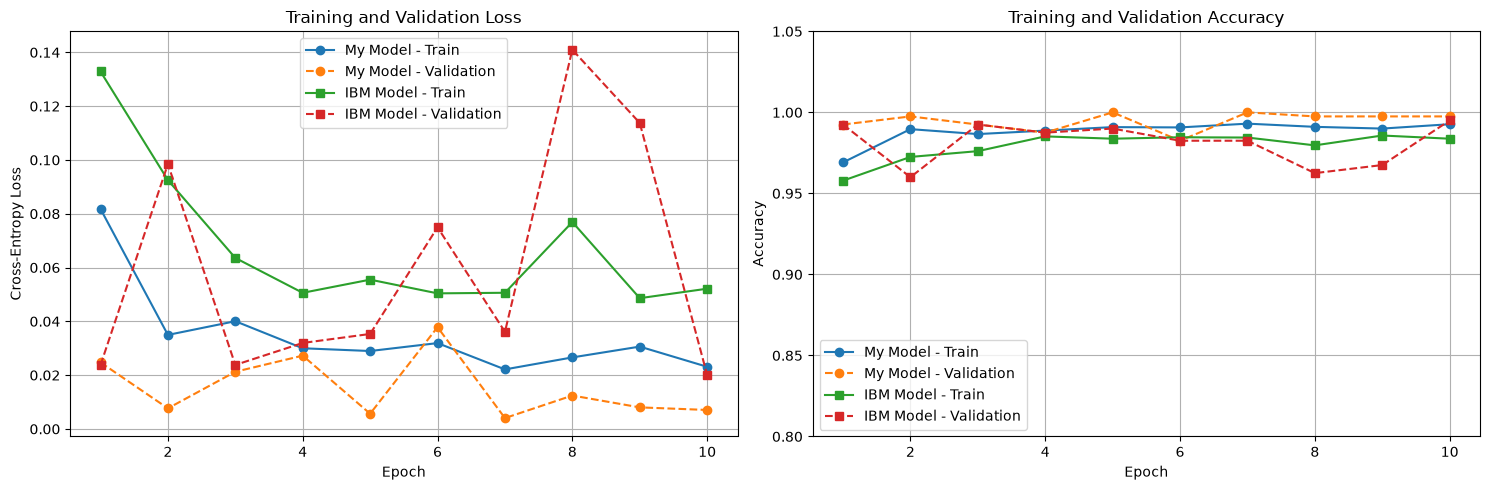

In [26]:
    # --------------------------------------------------
    # LIVE PLOTS
    # --------------------------------------------------

    clear_output(wait=True)

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    epoch_range = range(
        1, len(history["my_model"]["train_loss"]) + 1
    )

    # ==============================================
    # LOSS PLOT
    # ==============================================

    axes[0].plot(
        epoch_range,
        history["my_model"]["train_loss"],
        marker="o",
        label="My Model - Train"
    )

    axes[0].plot(
        epoch_range,
        history["my_model"]["val_loss"],
        marker="o",
        linestyle="--",
        label="My Model - Validation"
    )

    axes[0].plot(
        epoch_range,
        history["ibm_model"]["train_loss"],
        marker="s",
        label="IBM Model - Train"
    )

    axes[0].plot(
        epoch_range,
        history["ibm_model"]["val_loss"],
        marker="s",
        linestyle="--",
        label="IBM Model - Validation"
    )

    axes[0].set_title("Training and Validation Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Cross-Entropy Loss")
    axes[0].legend()
    axes[0].grid(True)

    # ==============================================
    # ACCURACY PLOT
    # ==============================================

    axes[1].plot(
        epoch_range,
        history["my_model"]["train_acc"],
        marker="o",
        label="My Model - Train"
    )

    axes[1].plot(
        epoch_range,
        history["my_model"]["val_acc"],
        marker="o",
        linestyle="--",
        label="My Model - Validation"
    )

    axes[1].plot(
        epoch_range,
        history["ibm_model"]["train_acc"],
        marker="s",
        label="IBM Model - Train"
    )

    axes[1].plot(
        epoch_range,
        history["ibm_model"]["val_acc"],
        marker="s",
        linestyle="--",
        label="IBM Model - Validation"
    )

    axes[1].set_title("Training and Validation Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].set_ylim(0.8, 1.05)
    axes[1].legend()
    axes[1].grid(True)

    plt.tight_layout()
    display(fig)
    plt.close(fig)

In [22]:
print("\n===== FINAL TRAINING HISTORY =====")

print(
    f"{'Epoch':<8}"
    f"{'Model':<15}"
    f"{'Train Loss':<14}"
    f"{'Val Loss':<14}"
    f"{'Train Acc':<14}"
    f"{'Val Acc':<14}"
)

print("-" * 75)

for i in range(epochs):
    for name in ["my_model", "ibm_model"]:
        print(
            f"{i+1:<8}"
            f"{name:<15}"
            f"{history[name]['train_loss'][i]:<14.4f}"
            f"{history[name]['val_loss'][i]:<14.4f}"
            f"{history[name]['train_acc'][i]:<14.4f}"
            f"{history[name]['val_acc'][i]:<14.4f}"
        )

print("=" * 75)

print("\n===== TRAINING TIME =====")

for name in ["my_model", "ibm_model"]:
    print(
        f"{name}: "
        f"{sum(history[name]['epoch_time']):.2f} seconds "
        f"(combined epoch timing)"
    )


===== FINAL TRAINING HISTORY =====
Epoch   Model          Train Loss    Val Loss      Train Acc     Val Acc       
---------------------------------------------------------------------------
1       my_model       0.0818        0.0247        0.9691        0.9925        
1       ibm_model      0.1329        0.0237        0.9579        0.9925        
2       my_model       0.0350        0.0077        0.9896        0.9975        
2       ibm_model      0.0925        0.0985        0.9725        0.9600        
3       my_model       0.0401        0.0213        0.9866        0.9925        
3       ibm_model      0.0636        0.0238        0.9761        0.9925        
4       my_model       0.0300        0.0273        0.9888        0.9875        
4       ibm_model      0.0506        0.0320        0.9852        0.9875        
5       my_model       0.0290        0.0057        0.9909        1.0000        
5       ibm_model      0.0555        0.0353        0.9838        0.9900        
6       

In [23]:
# import matplotlib.pyplot as plt

# epochs_range = range(1, len(loss_history['train']) + 1)

# # --- Loss ---
# plt.figure(figsize=(8, 5))
# plt.plot(epochs_range, loss_history['train'], label='Train Loss')
# plt.plot(epochs_range, loss_history['val'], label='Validation Loss')
# plt.xlabel('Epoch')
# plt.ylabel('Loss')
# plt.title('Training and Validation Loss')
# plt.legend()
# plt.grid(True)
# plt.show()


# # --- Accuracy ---
# plt.figure(figsize=(8, 5))
# plt.plot(epochs_range, acc_history['train'], label='Train Accuracy')
# plt.plot(epochs_range, acc_history['val'], label='Validation Accuracy')
# plt.xlabel('Epoch')
# plt.ylabel('Accuracy')
# plt.title('Training and Validation Accuracy')
# plt.legend()
# plt.grid(True)
# plt.show()


In [24]:
# print("\n===== TRAINING HISTORY =====")
# print(
#     f"{'Epoch':<8}"
#     f"{'Train Loss':<14}"
#     f"{'Val Loss':<14}"
#     f"{'Train Acc':<14}"
#     f"{'Val Acc':<14}"
# )

# for i in range(len(loss_history['train'])):
#     print(
#         f"{i+1:<8}"
#         f"{loss_history['train'][i]:<14.4f}"
#         f"{loss_history['val'][i]:<14.4f}"
#         f"{acc_history['train'][i]:<14.4f}"
#         f"{acc_history['val'][i]:<14.4f}"
#     )

In [25]:
# # Load the best saved model
# model.load_state_dict(torch.load(model_name, map_location=device))
# model.to(device)

# # Evaluate on the training set with random augmentation
# model.eval()

# train_loss_aug = 0.0
# train_correct_aug = 0
# train_total_aug = 0

# with torch.no_grad():
#     for images, labels in tqdm(train_loader, desc="Evaluating augmented train set"):
#         images, labels = images.to(device), labels.to(device)

#         outputs = model(images)
#         loss = criterion(outputs, labels)

#         train_loss_aug += loss.item()

#         preds = torch.argmax(outputs, dim=1)
#         train_correct_aug += (preds == labels).sum().item()
#         train_total_aug += labels.size(0)

# avg_train_loss_aug = train_loss_aug / len(train_loader)
# train_acc_aug = train_correct_aug / train_total_aug

# print(f"Augmented Train Loss: {avg_train_loss_aug:.4f}")
# print(f"Augmented Train Accuracy: {train_acc_aug:.4f}")
# print(f"Correct predictions: {train_correct_aug}/{train_total_aug}")


Training on : ===cuda=== with batch size: 8 & lr: 0.001
Epoch 1/3: 100% 725/725 [00:04<00:00, 155.54it/s]
Train Loss: 0.1600 | Val Loss: 0.1122
Train Acc: 0.9491 | Val Acc: 0.9650
Epoch 1 training completed in 4.88 seconds

Epoch 2/3: 100% 725/725 [00:04<00:00, 162.11it/s]
Train Loss: 0.1095 | Val Loss: 0.0321
Train Acc: 0.9626 | Val Acc: 0.9900
Epoch 2 training completed in 4.70 seconds

Epoch 3/3: 100% 725/725 [00:04<00:00, 164.77it/s]
Train Loss: 0.0821 | Val Loss: 0.0186
Train Acc: 0.9753 | Val Acc: 1.0000
Epoch 3 training completed in 4.64 seconds